# Day 46: Sales & Service Demand Forecasting System

**Dataset:** the cleaned daily, weekly, and monthly demand tables from Day 45 (four service lines,
October 2023 to September 2026)

This notebook is the second of four days in the Sales & Service Demand Forecasting System project.
It analyzes the **trend** and the **seasonality** of the demand and builds the **baseline
forecasting models** that the real forecasting model of Day 47 has to beat. Day 48 builds the future
demand dashboard and the business planning recommendations.

## 1. Import Libraries

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.tsa.seasonal import STL

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

DATA_DIR = Path("../datasets/veda_demand")
for sub in ("analysis", "forecasts"):
    (DATA_DIR / sub).mkdir(parents=True, exist_ok=True)

LINES = ["Internship Programs", "Training Programs", "IT Services", "Digital Services"]
# One fixed color per service line (validated categorical palette); the forecast methods use another set of colors
COLORS = {"Internship Programs": "#2a78d6", "Training Programs": "#eb6834", "IT Services": "#1baf7a", "Digital Services": "#eda100"}
METHOD_COLORS = ["#6250d6", "#e87ba4", "#008300"]
INK, INK_SOFT, GRID, SURFACE = "#0b0b0b", "#52514e", "#dcdad4", "#fcfcfb"
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.edgecolor": GRID, "axes.labelcolor": INK_SOFT, "xtick.color": INK_SOFT,
                     "ytick.color": INK_SOFT, "text.color": INK, "axes.titlecolor": INK, "axes.titleweight": "bold",
                     "axes.titlelocation": "left", "figure.facecolor": SURFACE, "axes.facecolor": SURFACE})


def clean_axes(ax, grid_axis="y"):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(axis=grid_axis, color=GRID, linewidth=0.7)
    ax.set_axisbelow(True)

## 2. Load the Cleaned Demand Tables

In [2]:
daily = pd.read_csv(DATA_DIR / "cleaned" / "demand_daily_cleaned.csv", parse_dates=["date"])
weekly = pd.read_csv(DATA_DIR / "cleaned" / "demand_weekly.csv", parse_dates=["week_start"])
monthly = pd.read_csv(DATA_DIR / "cleaned" / "demand_monthly.csv", parse_dates=["month"])
holidays = pd.read_csv(DATA_DIR / "reference" / "holiday_calendar.csv", parse_dates=["date"])

daily_units = daily.pivot(index="date", columns="service_line", values="demand_units")[LINES].asfreq("D")
weekly_units = weekly.pivot(index="week_start", columns="service_line", values="demand_units")[LINES]
month_days = monthly.groupby("month")["days"].first()
monthly_units = monthly.pivot(index="month", columns="service_line", values="demand_units")[LINES].div(month_days / 30.44, axis=0).asfreq("MS")

print("Daily:", daily_units.shape, "| weekly:", weekly_units.shape, "| monthly:", monthly_units.shape)
print("Monthly values are adjusted to a 30.44-day month, so short months do not look like dips.")

Daily: (1096, 4) | weekly: (156, 4) | monthly: (36, 4)
Monthly values are adjusted to a 30.44-day month, so short months do not look like dips.


## 3. Trend Analysis

The **trend** is the long-run direction of the demand once the yearly and weekly rhythms and the
noise are set aside. It is looked at in three ways: a smooth measure of the level (the rolling
52-week total), a decomposition of the monthly series into trend, season, and remainder (STL), and
the year-over-year growth.

**The level of demand: the rolling 52-week total**

A 52-week total contains every season exactly once, so it removes the yearly pattern and shows the
level of demand directly.

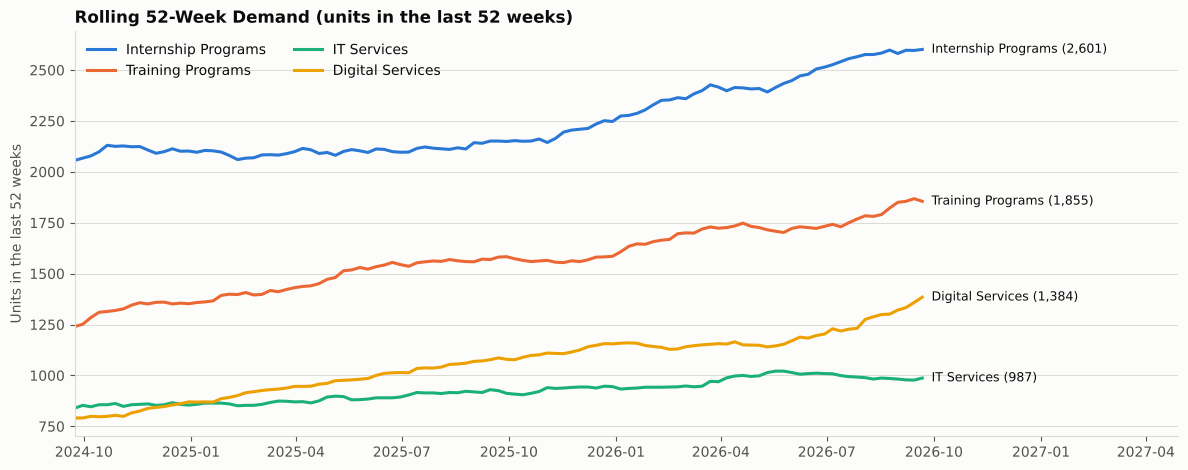

,first 52 weeks,last 52 weeks,growth_pct
service_line,,,
Internship Programs,2056.0,2601.0,26.5
Training Programs,1240.0,1855.0,49.6
IT Services,839.0,987.0,17.6
Digital Services,791.0,1384.0,75.0


In [3]:
rolling_year = weekly_units.rolling(52).sum().dropna()

fig, ax = plt.subplots(figsize=(12, 4.8))
for line in LINES:
    ax.plot(rolling_year.index, rolling_year[line], color=COLORS[line], linewidth=2.2, label=line)
    ax.text(rolling_year.index[-1] + pd.Timedelta(days=8), rolling_year[line].iloc[-1], f"{line} ({rolling_year[line].iloc[-1]:,.0f})", fontsize=9, va="center")
ax.set_title("Rolling 52-Week Demand (units in the last 52 weeks)")
ax.set_ylabel("Units in the last 52 weeks")
ax.set_xlim(rolling_year.index[0], rolling_year.index[-1] + pd.Timedelta(days=220))
ax.legend(loc="upper left", frameon=False, ncol=2)
clean_axes(ax)
plt.tight_layout()
plt.show()

first, last = rolling_year.iloc[0], rolling_year.iloc[-1]
pd.DataFrame({"first 52 weeks": first, "last 52 weeks": last, "growth_pct": (last / first - 1) * 100}).round(1)

**Decomposition: trend, season, and remainder (STL)**

STL splits a series into a smooth trend, a repeating seasonal pattern, and a remainder. It is applied
to the logarithm of the monthly demand, so the seasonal pattern is multiplicative (a percentage of the level) and not a fixed number of
units, which fits demand that grows. The straight line is a trend fitted only on the months before
June 2026 and extended to the end, to show what a plain trend forecast would have expected.

In [4]:
CUTOFF = pd.Timestamp("2026-05-01")      # the last month before the change in the last months
stl_results, fits_before, trend_rows = {}, {}, []
time_years = (monthly_units.index - monthly_units.index[0]).days.to_numpy() / 365.25

for line in LINES:
    log_series = np.log(monthly_units[line])
    result = STL(log_series, period=12, robust=False).fit()
    stl_results[line] = result
    deseasonalized = log_series - result.seasonal
    before = (monthly_units.index <= CUTOFF)
    fit_before = sm.OLS(deseasonalized[before].to_numpy(), sm.add_constant(time_years[before])).fit()
    fit_all = sm.OLS(deseasonalized.to_numpy(), sm.add_constant(time_years)).fit()
    trend_rows.append({"service_line": line,
                       "growth_pct_per_year_before_Jun2026": (np.exp(fit_before.params[1]) - 1) * 100,
                       "growth_pct_per_year_all_months": (np.exp(fit_all.params[1]) - 1) * 100,
                       "trend_units_per_month_start": np.exp(result.trend.iloc[0]), "trend_units_per_month_end": np.exp(result.trend.iloc[-1])})
    fits_before[line] = fit_before

trend_table = pd.DataFrame(trend_rows).set_index("service_line")
trend_table.round(1)

,growth_pct_per_year_before_Jun2026,growth_pct_per_year_all_months,trend_units_per_month_start,trend_units_per_month_end
service_line,,,,
Internship Programs,11.6,13.1,166.3,237.2
Training Programs,23.0,22.8,86.8,164.6
IT Services,9.3,7.7,67.7,81.2
Digital Services,31.6,31.7,51.0,122.4


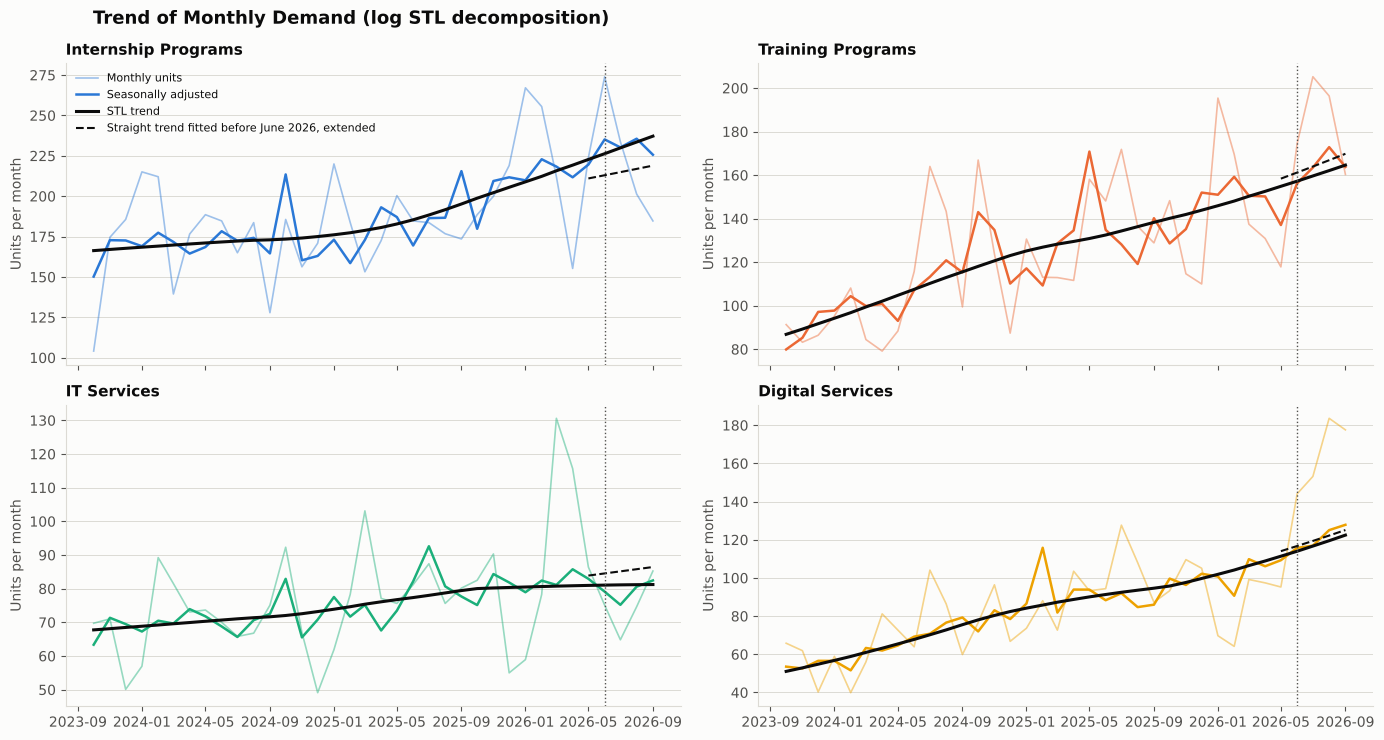

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7.5), sharex=True)
for ax, line in zip(axes.ravel(), LINES):
    result = stl_results[line]
    seasonally_adjusted = np.exp(np.log(monthly_units[line]) - result.seasonal)
    straight = np.exp(fits_before[line].params[0] + fits_before[line].params[1] * time_years)
    ax.plot(monthly_units.index, monthly_units[line], color=COLORS[line], alpha=0.45, linewidth=1.2, label="Monthly units")
    ax.plot(monthly_units.index, seasonally_adjusted, color=COLORS[line], linewidth=1.8, label="Seasonally adjusted")
    ax.plot(monthly_units.index, np.exp(result.trend), color=INK, linewidth=2.2, label="STL trend")
    ax.plot(monthly_units.index[monthly_units.index >= CUTOFF], straight[monthly_units.index >= CUTOFF], color=INK, linewidth=1.5, linestyle="--",
            label="Straight trend fitted before June 2026, extended")
    ax.axvline(pd.Timestamp("2026-06-01"), color=INK_SOFT, linestyle=":", linewidth=1)
    ax.set_title(line, fontsize=11)
    ax.set_ylabel("Units per month")
    clean_axes(ax)
axes[0, 0].legend(loc="upper left", frameon=False, fontsize=8)
fig.suptitle("Trend of Monthly Demand (log STL decomposition)", x=0.07, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

**Observation:** All four lines grow, but at very different speeds. The STL trend of Digital Services rises from about 51 to 122 units a month and that of Training Programs from about 87 to 165, while IT Services moves only from 68 to 81 and has been almost flat since late 2025. A straight line fitted to the seasonally adjusted months before June 2026 gives growth of 11.6%, 23.0%, 9.3%, and 31.6% a year for Internship, Training, IT, and Digital. These estimates are in the right order of size but noisy: with only 32 months, a single odd month moves the slope, and two lines are off by about 8 points (the simulation's true rates are given in the check below). The dashed line shows what a forecaster who trusted the old trend would have expected after June: Digital Services ends far above it and IT Services slightly below it. The decomposition itself hides part of the Digital lift, because with just three yearly cycles the seasonal part absorbs some of it (the seasonally adjusted Digital line ends near 128, while the raw month is near 178).

**Year-over-year growth in the last months**

Year-over-year growth compares a month with the same month a year earlier, so seasonality cancels out.
A sudden change in this number is the signal that the trend has changed.

In [6]:
yoy = (monthly_units / monthly_units.shift(12) - 1) * 100
yoy_table = yoy.loc["2025-10-01":].copy()
yoy_table.index = yoy_table.index.strftime("%b %Y")
print("Year-over-year growth of the monthly demand (%):")
yoy_table.round(1)

Year-over-year growth of the monthly demand (%):


service_line,Internship Programs,Training Programs,IT Services,Digital Services
month,,,,
Oct 2025,1.6,-11.2,-10.6,21.8
Nov 2025,27.9,-7.4,34.8,13.7
Dec 2025,28.2,25.8,12.0,57.4
Jan 2026,21.4,49.6,-4.8,-5.3
Feb 2026,39.1,50.0,0.0,-27.2
Mar 2026,38.5,21.7,26.7,36.5
Apr 2026,-10.0,17.3,50.0,-5.9
May 2026,11.8,-25.5,14.3,2.1
Jun 2026,48.4,17.8,-7.5,52.7


**Observation:** Year-over-year growth is very noisy for a single month: Training Programs goes from -25.5% in May 2026 to +43.9% in August 2026, and Digital Services shows -27.2% in February 2026, so one month alone proves nothing. The average tells the story better. Digital Services averaged +11.6% over October 2025 to May 2026 and +61.6% over June to September 2026 (with +103.5% in September), while IT Services moved from an average of +15.3% to -7.1%. A change in the trend therefore shows up in this table only after several months, which is a first reason why trend-based forecasts are late to react.

## 4. Seasonality Analysis

**Seasonality** is a pattern that repeats at a fixed interval. This demand has two: a **yearly**
pattern (some months are busier) and a **weekly** pattern (some weekdays are busier). The
calendar (public holidays) and the marketing campaigns also move the demand in a predictable way.

**Yearly seasonality: the seasonal index of each month**

The index is the seasonal part of the STL decomposition, averaged by calendar month. A value of 1.30
means that the month is typically 30% above the level of the year.

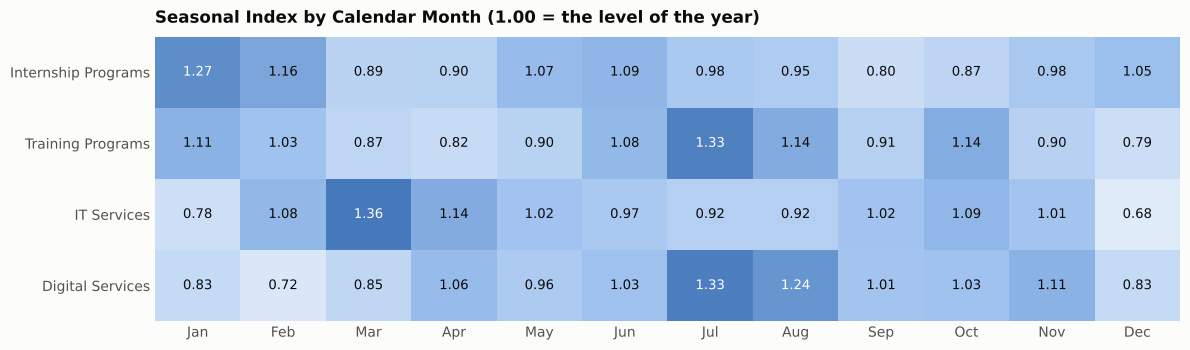

Peak month of each line: {'Internship Programs': 'Jan', 'Training Programs': 'Jul', 'IT Services': 'Mar', 'Digital Services': 'Jul'}


In [7]:
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
season_index = pd.DataFrame({line: np.exp(stl_results[line].seasonal).groupby(monthly_units.index.month).mean() for line in LINES}).T
season_index = season_index.div(season_index.mean(axis=1), axis=0)
season_index.columns = MONTHS

fig, ax = plt.subplots(figsize=(12, 3.6))
from matplotlib.colors import LinearSegmentedColormap
seq = LinearSegmentedColormap.from_list("seq_blue", ["#f0f5fc", "#9cc0ee", "#1f5aa6"])
ax.imshow(season_index.values, cmap=seq, vmin=0.6, vmax=1.5, aspect="auto")
for i in range(season_index.shape[0]):
    for j in range(season_index.shape[1]):
        v = season_index.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9.5, color="white" if v > 1.22 else INK)
ax.set_xticks(range(12))
ax.set_xticklabels(MONTHS)
ax.set_yticks(range(4))
ax.set_yticklabels(LINES)
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)
ax.set_title("Seasonal Index by Calendar Month (1.00 = the level of the year)", pad=10)
plt.tight_layout()
plt.show()

season_index.to_csv(DATA_DIR / "analysis" / "seasonal_index_by_month.csv", index_label="service_line")
peak = season_index.idxmax(axis=1)
print("Peak month of each line:", peak.to_dict())

**How strong is the seasonality?**

The strength of a seasonal pattern is `1 - Var(remainder) / Var(seasonal + remainder)`: 0 means no
pattern, and values close to 1 mean that the pattern dominates what is left after the trend. The yearly strength
is measured on the monthly data and the weekly strength on the daily data (STL with a period of 7 days).

In [8]:
rows = []
for line in LINES:
    yearly = stl_results[line]
    weekly_stl = STL(daily_units[line].astype(float), period=7, robust=True).fit()
    rows.append({"service_line": line,
                 "yearly_strength": max(0, 1 - yearly.resid.var() / (yearly.seasonal + yearly.resid).var()),
                 "weekly_strength": max(0, 1 - weekly_stl.resid.var() / (weekly_stl.seasonal + weekly_stl.resid).var())})
strength = pd.DataFrame(rows).set_index("service_line")
strength.round(2)

,yearly_strength,weekly_strength
service_line,,
Internship Programs,0.86,0.37
Training Programs,0.79,0.25
IT Services,0.91,0.33
Digital Services,0.90,0.29


**Holidays, campaigns, and the trend, estimated together**

Holidays and campaigns are separate from the yearly pattern, but they overlap with it (a
campaign in July looks like a July effect). A **Poisson regression** (a model for counts, with a log link, so
each effect is a percentage) estimates the trend, the month, the weekday, the holiday, and the campaign
effects at the same time, for each line. It is fitted on the days before June 2026, so the change in the
last months does not distort it, and it uses robust standard errors because the daily counts vary more than a Poisson count.

In [9]:
daily_model = daily.copy()
daily_model["t"] = (daily_model["date"] - daily_model["date"].min()).dt.days / 365.25
daily_model["month"] = daily_model["date"].dt.month
daily_model["weekday"] = daily_model["date"].dt.dayofweek
daily_model["holiday"] = daily_model["date"].isin(holidays["date"]).astype(int)
daily_model["campaign"] = daily_model["campaign_active"]
estimation = daily_model[daily_model["date"] < "2026-06-01"]

rows = []
for line in LINES:
    fit = smf.glm("demand_units ~ t + C(month) + C(weekday) + holiday + campaign", data=estimation[estimation["service_line"] == line],
                  family=sm.families.Poisson()).fit(cov_type="HC0")
    ci = fit.conf_int()
    rows.append({"service_line": line,
                 "growth_pct_per_year": (np.exp(fit.params["t"]) - 1) * 100, "growth_low": (np.exp(ci.loc["t", 0]) - 1) * 100, "growth_high": (np.exp(ci.loc["t", 1]) - 1) * 100,
                 "campaign_lift_pct": (np.exp(fit.params["campaign"]) - 1) * 100, "campaign_low": (np.exp(ci.loc["campaign", 0]) - 1) * 100, "campaign_high": (np.exp(ci.loc["campaign", 1]) - 1) * 100,
                 "holiday_effect_pct": (np.exp(fit.params["holiday"]) - 1) * 100, "holiday_low": (np.exp(ci.loc["holiday", 0]) - 1) * 100, "holiday_high": (np.exp(ci.loc["holiday", 1]) - 1) * 100})
effects = pd.DataFrame(rows).set_index("service_line")
effects.round(1).to_csv(DATA_DIR / "analysis" / "calendar_effects.csv")
effects.round(1)

,growth_pct_per_year,growth_low,growth_high,campaign_lift_pct,campaign_low,campaign_high,holiday_effect_pct,holiday_low,holiday_high
service_line,,,,,,,,,
Internship Programs,9.9,5.2,14.8,33.1,22.9,44.1,-51.3,-60.6,-39.8
Training Programs,19.1,13.2,25.4,26.4,14.9,39.1,-55.2,-66.4,-40.2
IT Services,12.5,5.9,19.6,15.8,2.2,31.2,-48.5,-64.4,-25.6
Digital Services,25.0,18.2,32.3,34.8,21.4,49.6,-44.0,-58.6,-24.3


**Check against the simulation (possible only because the data is simulated)**

The values that were used to generate the data on Day 45 are repeated here only to grade the analysis:
the growth was 10%, 14%, 16%, and 24% a year (continuous rate, which is 10.5%, 15.0%, 17.4%, and 27.1% a year), the campaigns lift demand by
30%, a holiday halves it, and the yearly pattern is the profile below.

In [10]:
TRUE_GROWTH = pd.Series({"Internship Programs": np.exp(0.10) - 1, "Training Programs": np.exp(0.14) - 1, "IT Services": np.exp(0.16) - 1, "Digital Services": np.exp(0.24) - 1}) * 100
TRUE_PROFILE = {   # relative demand for January to December used in the simulation
    "Internship Programs": [1.30, 1.20, 0.95, 0.85, 0.95, 1.25, 1.00, 0.85, 0.80, 0.90, 0.95, 1.00],
    "Training Programs":   [1.15, 0.95, 0.85, 0.80, 0.90, 1.10, 1.45, 1.05, 0.85, 0.90, 0.95, 0.75],
    "IT Services":         [0.90, 1.00, 1.30, 1.00, 0.95, 0.90, 0.95, 0.90, 1.05, 1.10, 0.95, 0.70],
    "Digital Services":    [0.85, 0.85, 0.90, 0.95, 1.00, 1.05, 1.25, 1.05, 0.95, 1.00, 1.10, 1.00]}

grading = pd.DataFrame({
    "growth_true_pct": TRUE_GROWTH, "growth_estimated_STL": trend_table["growth_pct_per_year_before_Jun2026"], "growth_estimated_regression": effects["growth_pct_per_year"],
    "campaign_true_pct": 30.0, "campaign_estimated_pct": effects["campaign_lift_pct"],
    "holiday_true_pct": -50.0, "holiday_estimated_pct": effects["holiday_effect_pct"],
    "season_correlation": [np.corrcoef(season_index.loc[line], np.array(TRUE_PROFILE[line]) / np.mean(TRUE_PROFILE[line]))[0, 1] for line in LINES],
    "peak_month_true": [MONTHS[int(np.argmax(TRUE_PROFILE[line]))] for line in LINES], "peak_month_estimated": peak}, index=LINES)
grading.round(2)

,growth_true_pct,growth_estimated_STL,growth_estimated_regression,campaign_true_pct,campaign_estimated_pct,holiday_true_pct,holiday_estimated_pct,season_correlation,peak_month_true,peak_month_estimated
Internship Programs,10.52,11.59,9.87,30.0,33.08,-50.0,-51.29,0.89,Jan,Jan
Training Programs,15.03,22.96,19.15,30.0,26.40,-50.0,-55.16,0.89,Jul,Jul
IT Services,17.35,9.25,12.55,30.0,15.77,-50.0,-48.53,0.92,Mar,Mar
Digital Services,27.12,31.62,25.04,30.0,34.76,-50.0,-44.01,0.86,Jul,Jul


**Observation:** The yearly pattern is strong and was recovered well. The peak months are right for all four lines (January for Internship, July for Training and Digital, March for IT), the shape correlates 0.86 to 0.92 with the profile used in the simulation, and the yearly seasonal strength is 0.79 to 0.91. The weekly pattern (weekday versus weekend) is weaker, 0.25 to 0.37, because daily counts are small and noisy, but it is systematic and matters for weekly planning. The regression, fitted only on the days before June 2026, estimates holidays at -44% to -55% of normal demand and campaigns at +16% to +35%, and all of its 95% intervals contain the true values (-50% and +30%). The IT campaign effect is the least certain (+15.8%, interval +2% to +31%) because IT had few campaign days. The regression was closer to the true growth than the STL line for all four lines (errors of 0.7, 4.1, 4.8, and 2.1 points against 1.1, 7.9, 8.1, and 4.5), because it separates holidays and campaigns from the trend. One warning: the seasonal index of Digital Services in August is 1.24 while the true value is about 1.05, because the lift that started in June was partly mistaken for season. This check is only possible because the data is simulated, and recovering patterns that were built into the data is easier than finding them in real data.

## 5. Baseline Forecasting Models

A **baseline** is the simplest forecast that is still reasonable. Any real model has to beat it,
otherwise the model is not worth its complexity. The forecasts are made for the **weekly** demand of each
line, because weekly totals are the level that planning (staffing and campaigns) needs and that is not drowned in daily noise.

**The test: forecast the next 26 weeks from an end date**

Time series must be split by time, never at random: the models see the history up to **March 22, 2026**
(130 weeks), and the forecasts are checked against the **26 weeks that follow** (March 30 to September 27, 2026).
The test period includes the change in the last months, which is the hard part on purpose.

In [11]:
TRAIN_END = pd.Timestamp("2026-03-23")          # the start of the last training week
SHIFT_START = pd.Timestamp("2026-06-01")        # the first week of the change in the last months
train = weekly_units[weekly_units.index <= TRAIN_END]
test = weekly_units[weekly_units.index > TRAIN_END]
print(f"Training weeks: {len(train)} ({train.index[0].date()} to {train.index[-1].date()})")
print(f"Test weeks:     {len(test)} ({test.index[0].date()} to {test.index[-1].date()}), of which from June 1: {int((test.index >= SHIFT_START).sum())}")

Training weeks: 130 (2023-10-02 to 2026-03-23)
Test weeks:     26 (2026-03-30 to 2026-09-21), of which from June 1: 17


**The baseline methods**

| Method | How it forecasts |
|---|---|
| Naive | the last observed week, repeated |
| Moving average (4 weeks) | the average of the last 4 weeks, repeated |
| Moving average (13 weeks) | the average of the last 13 weeks (a quarter), repeated |
| Seasonal naive | the value of the same week one year earlier (52 weeks before) |
| Seasonal naive with growth | the same week one year earlier, times the growth of the last 52 weeks over the 52 weeks before |
| Smoothed seasonal naive with growth | the average of the same week one year earlier and the weeks on either side, times the same growth factor |

The first three ignore seasonality (they assume that the next weeks look like the recent ones), and the last three
carry the yearly pattern and, in the last two, the trend. The smoothed version averages three weeks of last year so that
the noise of one single week is not copied into the forecast.

In [12]:
METHODS = ["Naive", "Moving average (4 weeks)", "Moving average (13 weeks)", "Seasonal naive", "Seasonal naive with growth", "Smoothed seasonal naive with growth"]
WEEK = pd.Timedelta(weeks=1)


def baseline_forecasts(history, horizon):
    """All baseline forecasts for one line, using only the history (a series indexed by week start)."""
    out = pd.DataFrame(index=horizon)
    out["Naive"] = history.iloc[-1]
    out["Moving average (4 weeks)"] = history.iloc[-4:].mean()
    out["Moving average (13 weeks)"] = history.iloc[-13:].mean()
    growth = history.iloc[-52:].sum() / history.iloc[-104:-52].sum()
    same_week = pd.Series([history.loc[w - 52 * WEEK] for w in horizon], index=horizon)
    smoothed = pd.Series([np.mean([history.loc[w - 53 * WEEK], history.loc[w - 52 * WEEK], history.loc[w - 51 * WEEK]]) for w in horizon], index=horizon)
    out["Seasonal naive"] = same_week
    out["Seasonal naive with growth"] = same_week * growth
    out["Smoothed seasonal naive with growth"] = smoothed * growth
    return out, growth


frames, growth_factors = [], {}
for line in LINES:
    forecast, growth_factors[line] = baseline_forecasts(train[line], test.index)
    forecast.insert(0, "actual", test[line])
    forecast.insert(0, "service_line", line)
    frames.append(forecast.reset_index(names="week_start"))
forecasts = pd.concat(frames, ignore_index=True)
forecasts["after_shift"] = forecasts["week_start"] >= SHIFT_START

print("Growth factor used by the growth baselines (last 52 weeks over the 52 weeks before):")
print({line: round(v, 3) for line, v in growth_factors.items()})
forecasts.round(1).head(6)

Growth factor used by the growth baselines (last 52 weeks over the 52 weeks before):
{'Internship Programs': np.float64(1.162), 'Training Programs': np.float64(1.216), 'IT Services': np.float64(1.112), 'Digital Services': np.float64(1.229)}


/tmp/ipykernel_425/1845019316.py:31: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  forecasts.round(1).head(6)


,week_start,service_line,actual,Naive,Moving average (4 weeks),Moving average (13 weeks),Seasonal naive,Seasonal naive with growth,Smoothed seasonal naive with growth,after_shift
0,2026-03-30,Internship Programs,35,57,51.8,55.9,46,53.4,47.6,False
1,2026-04-06,Internship Programs,30,57,51.8,55.9,48,55.8,46.5,False
2,2026-04-13,Internship Programs,42,57,51.8,55.9,26,30.2,42.2,False
3,2026-04-20,Internship Programs,33,57,51.8,55.9,35,40.7,40.3,False
4,2026-04-27,Internship Programs,38,57,51.8,55.9,43,50.0,46.1,False
5,2026-05-04,Internship Programs,43,57,51.8,55.9,41,47.6,57.3,False


**Forecast accuracy measures**

- **MAE** (mean absolute error): the average miss in units per week.
- **WAPE** (weighted absolute percentage error): the total absolute miss divided by the total actual demand. It
  is better than the usual MAPE for counts, because MAPE explodes in weeks with a small demand.
- **Bias**: the total forecast minus the total actual demand over the 26 weeks, as a percentage of the actual
  demand. A positive bias means over-forecasting, which is the number a planner uses for a total budget.

In [13]:
def metrics(actual, predicted):
    error = predicted - actual
    return {"MAE": error.abs().mean(), "WAPE_pct": error.abs().sum() / actual.sum() * 100, "bias_pct": error.sum() / actual.sum() * 100}


rows = []
for method in METHODS:
    for line in LINES:
        part = forecasts[forecasts["service_line"] == line]
        rows.append({"method": method, "service_line": line, **metrics(part["actual"], part[method])})
    total = forecasts.groupby("week_start")[["actual"] + METHODS].sum()
    rows.append({"method": method, "service_line": "All lines", **metrics(total["actual"], total[method])})
baseline_metrics = pd.DataFrame(rows)
baseline_metrics.round(2).to_csv(DATA_DIR / "forecasts" / "baseline_metrics.csv", index=False)

wape = baseline_metrics.pivot(index="method", columns="service_line", values="WAPE_pct").loc[METHODS][LINES + ["All lines"]]
bias = baseline_metrics.pivot(index="method", columns="service_line", values="bias_pct").loc[METHODS][LINES + ["All lines"]]
print("WAPE (%) over the 26 test weeks, lower is better:")
display(wape.round(1))
print("Bias (%) over the 26 test weeks (positive = the forecast was too high):")
bias.round(1)

WAPE (%) over the 26 test weeks, lower is better:


service_line,Internship Programs,Training Programs,IT Services,Digital Services,All lines
method,,,,,
Naive,22.1,27.7,107.4,41.8,13.8
Moving average (4 weeks),18.3,27.2,73.8,32.4,12.8
Moving average (13 weeks),21.1,25.9,26.0,45.9,12.5
Seasonal naive,25.0,30.9,28.2,37.5,19.9
Seasonal naive with growth,21.8,30.9,31.7,33.4,15.9
Smoothed seasonal naive with growth,14.9,26.7,27.1,26.9,10.3


Bias (%) over the 26 test weeks (positive = the forecast was too high):


service_line,Internship Programs,Training Programs,IT Services,Digital Services,All lines
method,,,,,
Naive,17.3,-12.1,107.4,-41.6,7.7
Moving average (4 weeks),6.5,-10.1,71.5,-28.5,2.6
Moving average (13 weeks),15.1,2.5,8.4,-45.9,-3.7
Seasonal naive,-13.8,-12.9,-3.3,-27.3,-15.3
Seasonal naive with growth,0.2,5.9,7.6,-10.6,0.2
Smoothed seasonal naive with growth,-0.4,5.8,7.7,-10.9,-0.1


**Before and after the change in the last months**

The test period is split at June 1, 2026. The accuracy before the change shows how well a method
handles a normal period, and the accuracy after it shows what happens when the future differs from the past.

In [14]:
rows = []
for period, mask in [("March 30 to May 31 (9 weeks)", ~forecasts["after_shift"]), ("June 1 to September 27 (17 weeks)", forecasts["after_shift"])]:
    part_all = forecasts[mask]
    total = part_all.groupby("week_start")[["actual"] + METHODS].sum()
    for method in METHODS:
        rows.append({"period": period, "method": method, "service_line": "All lines", **metrics(total["actual"], total[method])})
        for line in LINES:
            part = part_all[part_all["service_line"] == line]
            rows.append({"period": period, "method": method, "service_line": line, **metrics(part["actual"], part[method])})
by_period = pd.DataFrame(rows)

print("WAPE (%) of all lines together:")
display(by_period[by_period["service_line"] == "All lines"].pivot(index="method", columns="period", values="WAPE_pct").loc[METHODS].round(1))
print("Bias (%) of the best-performing growth baseline (Smoothed seasonal naive with growth), by line:")
by_period[by_period["method"] == "Smoothed seasonal naive with growth"].pivot(index="service_line", columns="period", values="bias_pct").loc[LINES + ["All lines"]].round(1)

WAPE (%) of all lines together:


period,June 1 to September 27 (17 weeks),March 30 to May 31 (9 weeks)
method,,
Naive,8.3,27.2
Moving average (4 weeks),9.3,21.2
Moving average (13 weeks),11.9,13.9
Seasonal naive,21.8,15.3
Seasonal naive with growth,13.2,22.4
Smoothed seasonal naive with growth,8.6,14.4


Bias (%) of the best-performing growth baseline (Smoothed seasonal naive with growth), by line:


period,June 1 to September 27 (17 weeks),March 30 to May 31 (9 weeks)
service_line,,
Internship Programs,-6.3,12.9
Training Programs,-3.6,32.6
IT Services,24.3,-15.4
Digital Services,-21.5,23.5
All lines,-6.0,14.2


**The forecasts against what happened**

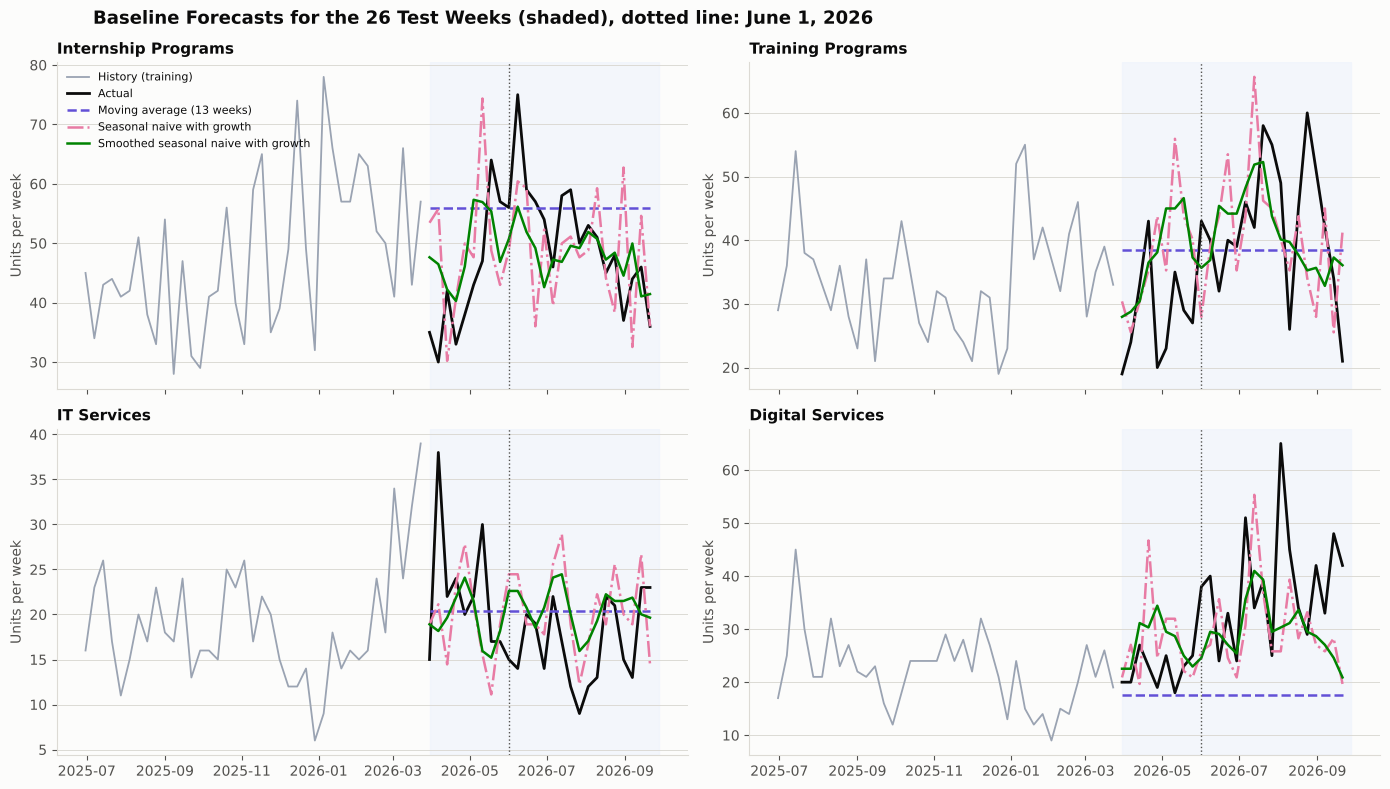

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
show = {"Moving average (13 weeks)": METHOD_COLORS[0], "Seasonal naive with growth": METHOD_COLORS[1], "Smoothed seasonal naive with growth": METHOD_COLORS[2]}
for ax, line in zip(axes.ravel(), LINES):
    part = forecasts[forecasts["service_line"] == line].set_index("week_start")
    history = train[line].iloc[-39:]
    ax.plot(history.index, history, color="#9aa3b2", linewidth=1.3, label="History (training)")
    ax.plot(part.index, part["actual"], color=INK, linewidth=2, label="Actual")
    for (method, color), style in zip(show.items(), ["--", "-.", "-"]):
        ax.plot(part.index, part[method], color=color, linewidth=1.8, linestyle=style, label=method)
    ax.axvline(SHIFT_START, color=INK_SOFT, linestyle=":", linewidth=1)
    ax.axvspan(test.index[0], test.index[-1] + 7 * pd.Timedelta(days=1), color="#eef3fb", alpha=0.6, zorder=0)
    ax.set_title(line, fontsize=11)
    ax.set_ylabel("Units per week")
    clean_axes(ax)
axes[0, 0].legend(loc="upper left", frameon=False, fontsize=8)
fig.suptitle("Baseline Forecasts for the 26 Test Weeks (shaded), dotted line: June 1, 2026", x=0.07, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

**Observation:** Three findings stand out. First, methods that ignore seasonality break at turning points: the last training week fell in the March peak of IT Services, so the naive forecast carried that peak forward and missed by 107.4% (the 4-week average by 73.8%), while the 13-week average, which spans a longer window, recovered to 26.0%. Second, growth matters: the seasonal naive forecast is 15.3% too low in total because it repeats last year's level, and multiplying it by the growth of the last 52 weeks removes that bias (+0.2%) and lowers the WAPE of the total from 19.9% to 15.9%; averaging the same week with its two neighbours reduces the noise of one year of history and lowers it to 10.3%, the best baseline overall. It is not the best in every line, though, because the 13-week average is slightly better for Training (25.9% against 26.7%) and IT (26.0% against 27.1%). Third, the numbers for the total hide what happens in the lines. After June 1 the best baseline is 21.5% too low for Digital Services and 24.3% too high for IT Services, and these two errors cancel in the total (-6.0%). The naive forecast has the lowest total WAPE after June (8.3%), but only because errors cancel; its errors per line are far larger. Before June the forecasts are too high in all lines except IT (+14.2% in total), possibly because spring 2025, the year these baselines copy, was unusually strong. Weekly counts are small and noisy, so even the best baseline misses by 15% to 27% per line, and this noise is a limit that no model can remove. One caveat: choosing the best baseline by its test result is slightly flattering to it, so its score is the one to beat on Day 47, not a guaranteed level.

In [16]:
forecasts_out = forecasts.copy()
forecasts_out["week_start"] = forecasts_out["week_start"].dt.strftime("%Y-%m-%d")
forecasts_out.round(2).to_csv(DATA_DIR / "forecasts" / "baseline_forecasts_weekly.csv", index=False)

print("Saved in", DATA_DIR)
print("  analysis/seasonal_index_by_month.csv   rows:", len(season_index))
print("  analysis/calendar_effects.csv          rows:", len(effects))
print("  forecasts/baseline_forecasts_weekly.csv rows:", len(forecasts_out), "(26 weeks x 4 lines)")
print("  forecasts/baseline_metrics.csv          rows:", len(baseline_metrics))

Saved in ../datasets/veda_demand
  analysis/seasonal_index_by_month.csv   rows: 4
  analysis/calendar_effects.csv          rows: 4
  forecasts/baseline_forecasts_weekly.csv rows: 104 (26 weeks x 4 lines)
  forecasts/baseline_metrics.csv          rows: 30


## Outcome

The demand grows in every line (about 10% to 25% a year before June 2026), follows a strong yearly pattern (the peaks are in January, July, March, and July for Internship, Training, IT, and Digital) and a weaker weekly one, falls by about half on holidays, and rises by roughly 15% to 35% in campaign periods. A simple baseline that repeats last year's pattern, smoothed over three weeks and multiplied by the recent growth, forecasts the weekly total of the 26 test weeks with a WAPE of 10.3% and almost no bias. The same baseline misses by 21.5% and 24.3% in the two lines that changed after June 1, which shows the main limit of every method built on history: it cannot know about a change that has not happened yet. Day 47 builds a statistical model and a machine learning model with the same training and test weeks and judges them against these saved baselines (`forecasts/baseline_metrics.csv`), with the smoothed seasonal naive forecast with growth as the benchmark to beat and the 13-week average as the simplest one.